## Part A — Existing Energy Forecast from the early phase of the project 

#### Data derived from SMAD related to Germany Electricity consumption or Grid Load
#####  The objective is to forecast the Grod load over a larger period of time with greater accuracy (more than 2 years)
##### 1. Downloading the 3 datatset of Interest
##### 2. dealing with missing values and outliers (graphical checks)
##### 3. Merge the 3 datasets

In [1]:
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import requests
import pandas as pd

Production  = pd.read_csv("/Users/jeanmiccheltia/Documents/Electricity Germany Data.csv", sep=";", header=0)
Production = Production.rename(columns={
              "Datum von": "date",
              "Datum bis": "Date to",
              "Biomasse [MWh] Berechnete Auflösungen": "Biomass [MWh]",
              "Wasserkraft [MWh] Berechnete Auflösungen": "Hydropower [MWh]",
              "Wind Offshore [MWh] Berechnete Auflösungen":	"Offshore Wind [MWh]",
              "Wind Onshore [MWh] Berechnete Auflösungen": "Onshore Wind [MWh]",
              "Photovoltaik [MWh] Berechnete Auflösungen":"Photovoltaics [MWh]",
              "Sonstige Erneuerbare [MWh] Berechnete Auflösungen":"Other renewables [MWh]",
              "Kernenergie [MWh] Berechnete Auflösungen":"Nuclear energy [MWh]",
              "Braunkohle [MWh] Berechnete Auflösungen":"Lignite [MWh]",
              "Steinkohle [MWh] Berechnete Auflösungen": "Hard coal [MWh]",
              "Erdgas [MWh] Berechnete Auflösungen": "Natural gas [MWh]",
              "Pumpspeicher [MWh] Berechnete Auflösungen":"Pumped-storage [MWh]",
              "Sonstige Konventionelle [MWh] Berechnete Auflösungen": "Other Conventional [MWh]",
              "Netzlast [MWh] Berechnete Auflösungen": "Grid load [MWh]"
})
cols = Production.columns.drop("date")
Production["date"]=pd.to_datetime(Production["date"], format="%d.%m.%y")
Production[cols] = (
    Production[cols]
    .replace({r"\.": "", ",": "."}, regex=True)
    .apply(pd.to_numeric, errors="coerce")
)
Production["Other renewables [MWh]"] = Production["Other renewables [MWh]"].ffill()
Production["Pumped-storage [MWh]"] = Production["Pumped-storage [MWh]"].ffill()

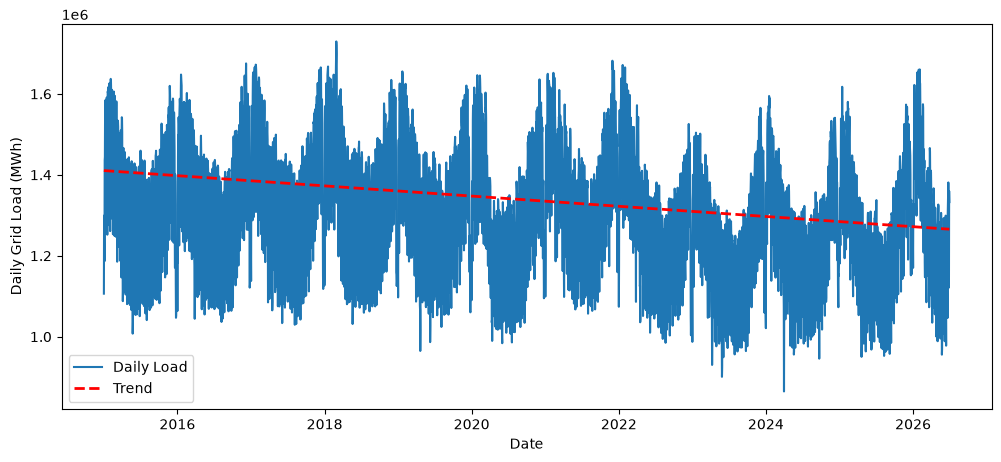

In [2]:
daily_consumption = (
    Production.groupby(Production["date"].dt.date)["Grid load [MWh]"]
              .sum()
)

x = np.arange(len(daily_consumption))
y = daily_consumption.values

z = np.polyfit(x, y, 1)
trend = np.poly1d(z)

plt.figure(figsize=(12, 5))
plt.plot(daily_consumption.index, y, label="Daily Load")
plt.plot(daily_consumption.index, trend(x), 'r--', linewidth=2, label="Trend")

plt.xlabel("Date")
plt.ylabel("Daily Grid Load (MWh)")
plt.legend()
plt.show()

<div style="text-align:left;">
    <span style="color: blue; font-size:18px; font-weight:bold;">
        Lets integrate Temperature and weather Inputs
    </span>
</div>

In [3]:
cities = {
    "Berlin": (52.52, 13.41),
    "Hamburg": (53.55, 10.00),
    "Munich": (48.14, 11.58),
    "Cologne": (50.94, 6.96),
    "Frankfurt": (50.11, 8.68),
    "Leipzig": (51.34, 12.37),
    "Stuttgart": (48.78, 9.18),
    "Bremen": (53.08, 8.80)
}

start_date = "2015-01-01"
end_date = "2026-06-30"

dfs = []

for city, (lat, lon) in cities.items():
    url = (
        "https://archive-api.open-meteo.com/v1/archive"
        f"?latitude={lat}"
        f"&longitude={lon}"
        f"&start_date={start_date}"
        f"&end_date={end_date}"
        "&daily=temperature_2m_mean"
        "&timezone=Europe/Berlin"
    )

    response = requests.get(url)
    response.raise_for_status()

    data = response.json()["daily"]

    df = pd.DataFrame({
        "date": data["time"],
        city: data["temperature_2m_mean"]
    })

    dfs.append(df)


result = dfs[0]
for df in dfs[1:]:
    result = result.merge(df, on="date")

result["Germany_avg_temp"] = result.iloc[:, 1:].mean(axis=1)

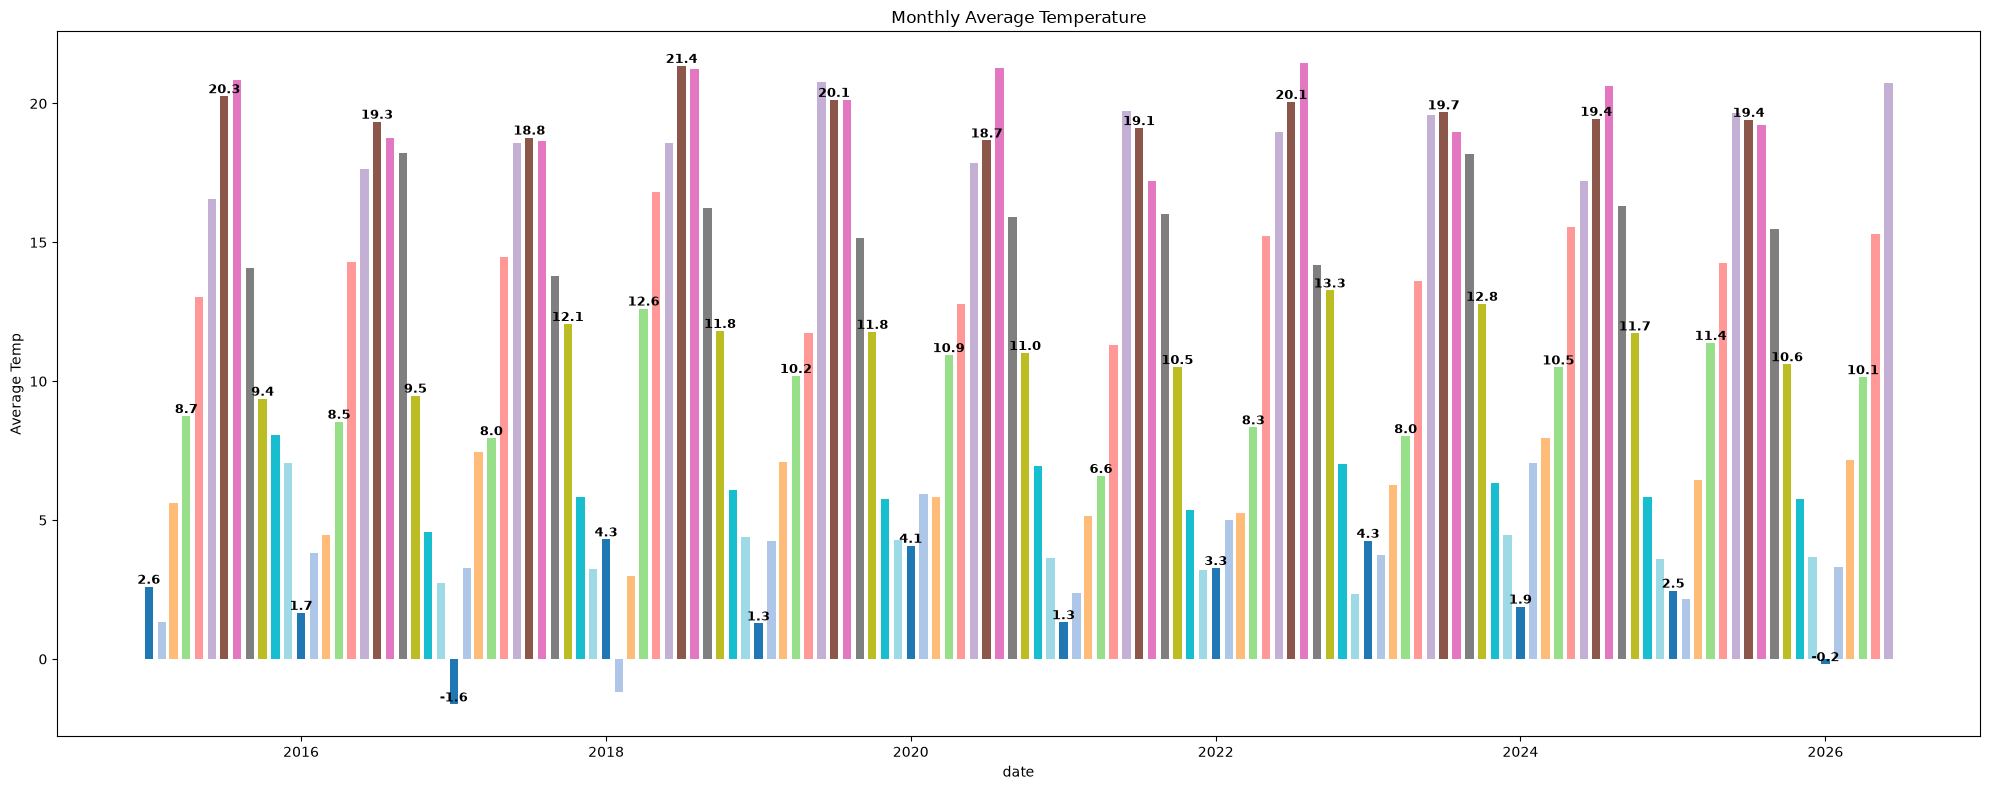

In [4]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

result["Germany_avg_temp"]=result["Germany_avg_temp"].round(1)

result["date"]= pd.to_datetime(result["date"])

monthly = (
    result.groupby(pd.Grouper(key="date", freq="MS"))["Germany_avg_temp"]
    .mean()
    .reset_index()
)
month_colors = plt.colormaps["tab20"].resampled(12)
colors =[month_colors(d.month - 1) for d in monthly["date"]]
plt.figure(figsize=(20,8))
bars = plt.bar(monthly["date"], monthly["Germany_avg_temp"], width=20, color=colors)
label_months = {1,4,7,10}
for bar, d, val in zip(bars, monthly["date"], monthly["Germany_avg_temp"]):
    if d.month in label_months:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{val:.1f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )
plt.xlabel("date")
plt.ylabel("Average Temp")
plt.title("Monthly Average Temperature")
plt.tight_layout()
plt.show()

<div style="text-align:left;">
    <span style="color: blue; font-size:18px; font-weight:bold;">
        Lets download Industrial Production
    </span>
</div>

In [5]:
Index_Production= pd.read_csv("/Users/jeanmiccheltia/Downloads/Production Index.csv", sep=";", header=0)
Index_Production["TIME"] = pd.to_datetime(Index_Production["TIME"], format="%d.%m.%y")
Index_Production["Germany"] =(Index_Production["Germany"]
                .astype(str)
                .str.strip()
                .str.replace(".","",regex=False)
                .str.replace(",",".",regex=False)
               )

Index_Production["Germany"]= pd.to_numeric(Index_Production["Germany"], errors="coerce")

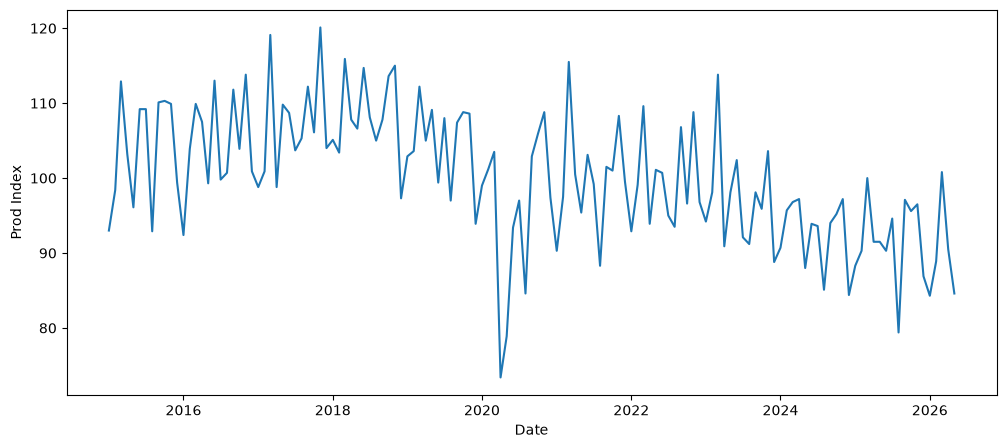

In [6]:
plt.figure(figsize=(12,5))
plt.plot(Index_Production["TIME"], Index_Production["Germany"])
plt.xlabel("Date")
plt.ylabel("Prod Index")
plt.show()

#### Merge the 2 datasets using date on left (Weather and SMAD data)

In [7]:
merged = Production.merge(
    result,
    on="date",
    how="left",
    indicator=True
)

print(merged["_merge"].value_counts())

_merge
both          4199
left_only        0
right_only       0
Name: count, dtype: int64


##### Lets see the correlation among variables particularly those with Load and load Price

<Axes: >

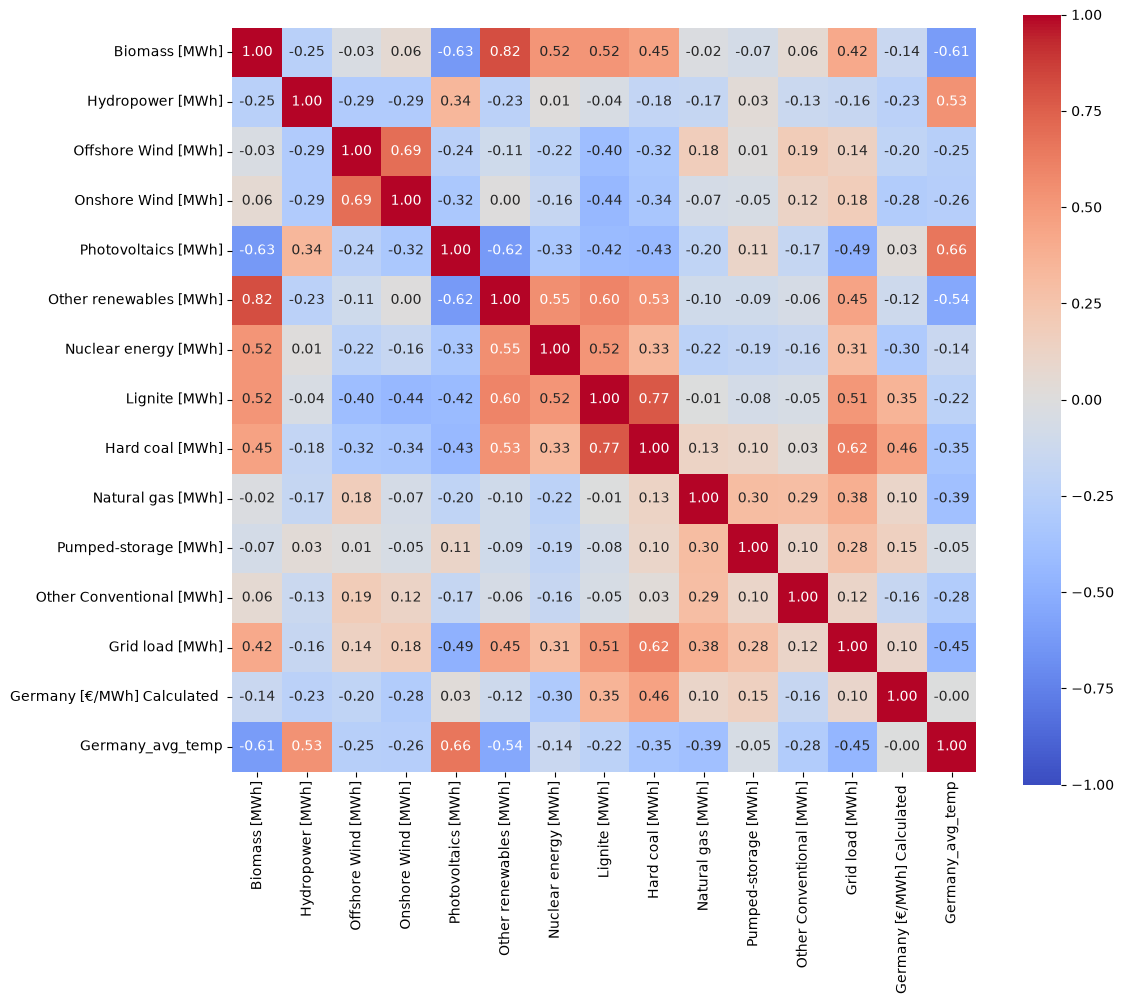

In [8]:
import seaborn as sns

merged = merged.drop(columns=['Berlin', 'Hamburg', 'Munich', 'Cologne', 'Frankfurt', 'Leipzig', 'Stuttgart', 'Bremen'])

corr = merged.select_dtypes(include="float").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,      
    cmap="coolwarm", 
    vmin=-1,
    vmax=1,
    square=True,
    fmt=".2f"
)

<div style="text-align:left;">
    <span style="color: blue; font-size:18px; font-weight:bold;">
        Lets add the dataset Industrial Production to the merge dataset
    </span>
</div>

##### before doing so lets remove the seasonality in the Production
The main reason is to make the production index represent the underlying level of economic/industrial activity, rather than predictable seasonal patterns.

In [9]:
from statsmodels.tsa.seasonal import seasonal_decompose

Index_Production = Index_Production.rename(columns={
              "TIME": "date","Germany":"prod_index"})
monthly_prod = Index_Production.set_index("date")["prod_index"].asfreq("MS")

decomp = seasonal_decompose(monthly_prod, model="additive", period=12)

Index_Production = Index_Production.set_index("date")
Index_Production["production_deseasonalized"] = decomp.trend + decomp.resid
Index_Production = Index_Production.reset_index()

Index_Production["month"] = Index_Production["date"].dt.to_period("M")
merged["month"] = merged["date"].dt.to_period("M")

merged = merged.drop(columns=["production_deseasonalized"], errors="ignore")  

merged = merged.merge(
    Index_Production[["month", "production_deseasonalized","prod_index"]],
    on="month",
    how="left"
)

In [10]:
merged["production_deseasonalized"] = merged["production_deseasonalized"].bfill().ffill()
print(merged["production_deseasonalized"].isna().sum())  
runs = merged["production_deseasonalized"].ne(merged["production_deseasonalized"].shift()).cumsum()

0


## Part A-1 Start of the Forecasting Process

##### 1. No outliers, values in 2020 reflect Covid
##### 2. Missing values were replaced with values of cells above (one of the many methods to fil in missing values)
##### 3. some further columns need to be created for days of the week)

In [11]:
runs = merged["production_deseasonalized"].ne(merged["production_deseasonalized"].shift()).cumsum()
run_sizes = merged.groupby(runs).size()
longest_run_id = run_sizes.idxmax()
print(merged[runs == longest_run_id]["date"].agg(["min", "max"]))

min   2025-11-01
max   2026-06-30
Name: date, dtype: datetime64[ns]


In [12]:
merged["day_of_week"] = merged["date"].dt.dayofweek
merged["is_weekend"] = merged["day_of_week"].isin([5,6]).astype(int)

import holidays

Germany_holidays = holidays.Germany(years=range(2015,2027))
merged["is_holiday"]= merged["date"].isin(Germany_holidays).astype(int)

dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)
merged = pd.concat([merged, dow_dummies], axis=1)

/var/folders/np/v9js13r17k9_qp03z_bwglkh0000gn/T/ipykernel_16905/2022983347.py:7: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  merged["is_holiday"]= merged["date"].isin(Germany_holidays).astype(int)


In [13]:
base_heating = 15.0
base_cooling = 20.0

merged["HDD"] = (base_heating - merged["Germany_avg_temp"]).clip(lower=0)
merged["CDD"] = (merged["Germany_avg_temp"] - base_cooling).clip(lower=0)

for lag in [1,2,3]:
    merged[f"HDD_lag{lag}"] = merged["HDD"].shift(lag)
    merged[f"CDD_lag{lag}"] = merged["CDD"].shift(lag)
merged["HDD_roll3"]= merged["HDD"].rolling(window=3).mean()
merged["CDD_roll3"]= merged["CDD"].rolling(window=3).mean()

merged["HDD_roll7"]= merged["HDD"].rolling(window=7).mean()
merged["CDD_roll7"]= merged["CDD"].rolling(window=7).mean()

##### retaining variables holding valuables information for the Forecast

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

candidate_vars = [
    "HDD_roll3", "CDD_roll3", "HDD_roll7", "CDD_roll7",
    "HDD", "CDD", "is_weekend", "is_holiday",
    "Germany_avg_temp", "prod_index","day_of_week","production_deseasonalized"
]

X = merged[candidate_vars].dropna().astype(float)

vif_data = pd.DataFrame()

vif_data["variable"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values(by="VIF", ascending=False)) 

                     variable         VIF
11  production_deseasonalized  472.959817
9                  prod_index  359.801570
0                   HDD_roll3  105.262546
4                         HDD   71.644159
8            Germany_avg_temp   58.945481
2                   HDD_roll7   40.323842
1                   CDD_roll3    8.774302
10                day_of_week    8.627891
5                         CDD    5.084177
3                   CDD_roll7    4.667323
6                  is_weekend    3.732245
7                  is_holiday    1.038162


In [15]:
final_vars = ["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_weekend", "is_holiday"]


X = merged[final_vars].dropna().astype(float)

vif_data = pd.DataFrame()
vif_data["variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data.sort_values("VIF", ascending=False))

                    variable       VIF
2                  CDD_roll7  4.876876
1                  CDD_roll3  4.625709
3  production_deseasonalized  2.992514
0                  HDD_roll3  2.309934
4                 is_weekend  1.398547
5                 is_holiday  1.030114


##### create a baseline model, NB: The baseline model were created looking at the ACF, PACF graph the appropriate 
##### lag to choose would be an ARIMA (1, 0, 1)x(1,0,1) or (3,0,2)x(1,0,1) but the BIC for the later was lower then choosen
##### Note that among all models Prophet, LSTM the Sarimax was choosen as best model

## Part A-2 Choosing the Model

In [16]:
import statsmodels.api as sm

dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)

X = pd.concat([merged[final_vars], dow_dummies], axis=1)
X = sm.add_constant(X.astype(float))
y = merged["Grid load [MWh]"]

valid = X.notna().all(axis=1) & y.notna()
model = sm.OLS(y[valid], X[valid]).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        Grid load [MWh]   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.831
Method:                 Least Squares   F-statistic:                     1868.
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        09:47:50   Log-Likelihood:                -52577.
No. Observations:                4193   AIC:                         1.052e+05
Df Residuals:                    4181   BIC:                         1.053e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [17]:
dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)

exog_vars = pd.concat([
    merged[["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_holiday","is_weekend"]],
    dow_dummies
], axis=1)

y = merged["Grid load [MWh]"]

valid = exog_vars.notna().all(axis=1) & y.notna()
y_valid = y[valid].reset_index(drop=True)
exog_valid = exog_vars[valid].astype(float).reset_index(drop=True)
merged_dates = merged.loc[valid, "date"].reset_index(drop=True)

test_size = 840

y_train, y_test = y_valid.iloc[:-test_size], y_valid.iloc[-test_size:]
exog_train, exog_test = exog_valid.iloc[:-test_size], exog_valid.iloc[-test_size:]

from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=(3,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
fit = model.fit(disp=False)
print(fit.summary())

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                      SARIMAX Results                                      
Dep. Variable:                     Grid load [MWh]   No. Observations:                 3353
Model:             SARIMAX(3, 0, 2)x(1, 0, [1], 7)   Log Likelihood              -40582.746
Date:                             Mon, 21 Sep 2026   AIC                          81205.492
Time:                                     09:47:56   BIC                          81327.785
Sample:                                          0   HQIC                         81249.239
                                            - 3353                                         
Covariance Type:                               opg                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
HDD_roll3                  1.468e+04    731.819     20.066      0.000    1.3

In [18]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

forecast = fit.forecast(steps=test_size, exog=exog_test)
mape = mean_absolute_percentage_error(y_test, forecast)
rmse = np.sqrt(mean_squared_error(y_test, forecast))
print(f"MAPE: {mape:.2%}, RMSE: {rmse:.2f}")

MAPE: 6.10%, RMSE: 99128.56


##### The first MAPE stands at 6.1% with an RMSE at 99129 Mwh 

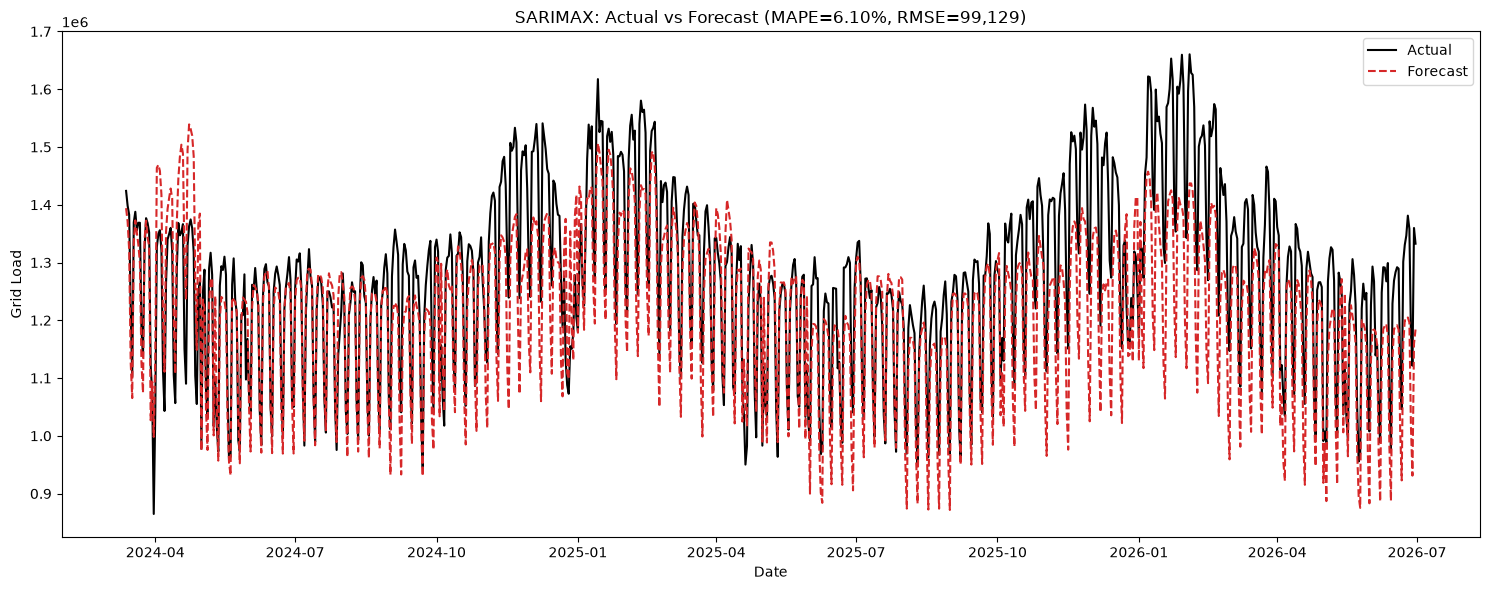

In [19]:
test_dates = merged_dates.iloc[-test_size:]

plt.figure(figsize=(15, 6))
plt.plot(test_dates, y_test.values, label="Actual", color="black", linewidth=1.5)
plt.plot(test_dates, forecast.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title(f"SARIMAX: Actual vs Forecast (MAPE={mape:.2%}, RMSE={rmse:,.0f})")
plt.legend()
plt.tight_layout()
plt.show()

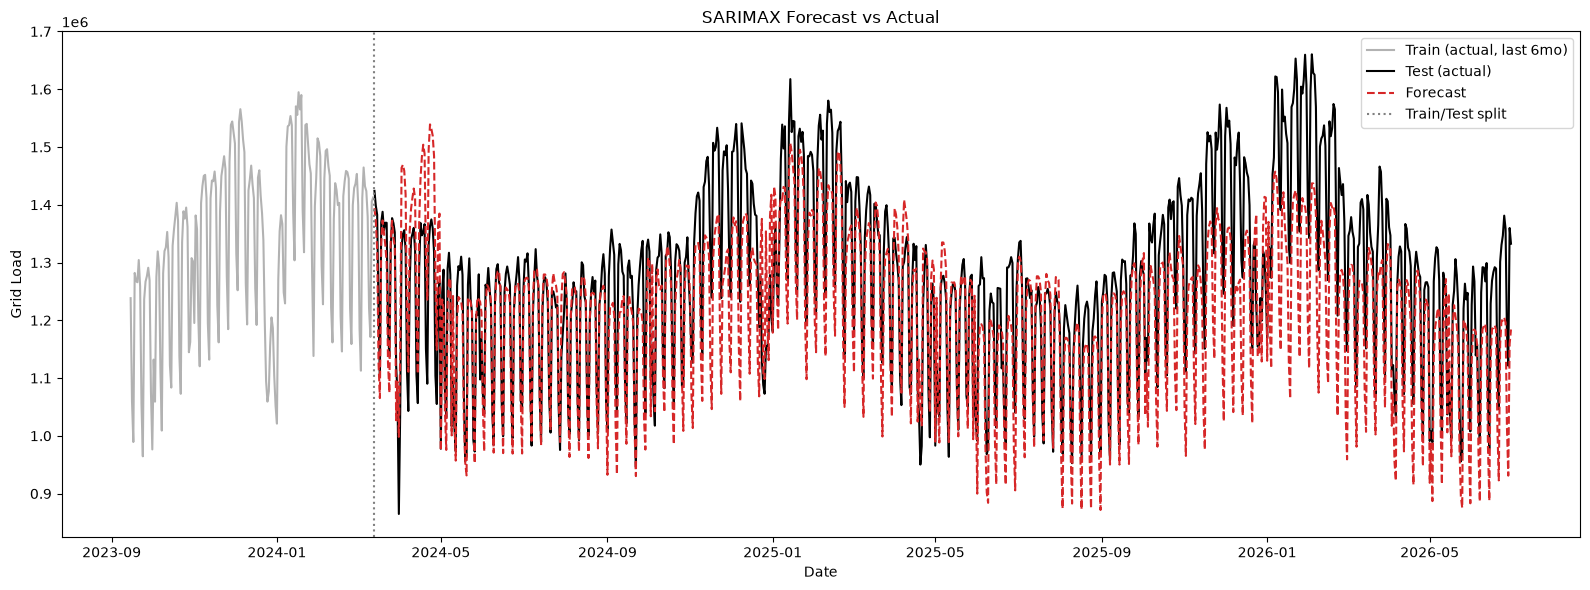

In [20]:
train_dates = merged_dates.iloc[:-test_size]

plt.figure(figsize=(16, 6))
plt.plot(train_dates.iloc[-180:], y_train.values[-180:], label="Train (actual, last 6mo)", color="grey", alpha=0.6)
plt.plot(test_dates, y_test.values, label="Test (actual)", color="black", linewidth=1.5)
plt.plot(test_dates, forecast.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.axvline(test_dates.iloc[0], color="grey", linestyle=":", label="Train/Test split")
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title("SARIMAX Forecast vs Actual")
plt.legend()
plt.tight_layout()
plt.show()

##### Forecast at the last quarter of 2024 and in large part of Q4 2025 and Q1 of 2026 not close to actual value despite  MAPE 6.1%

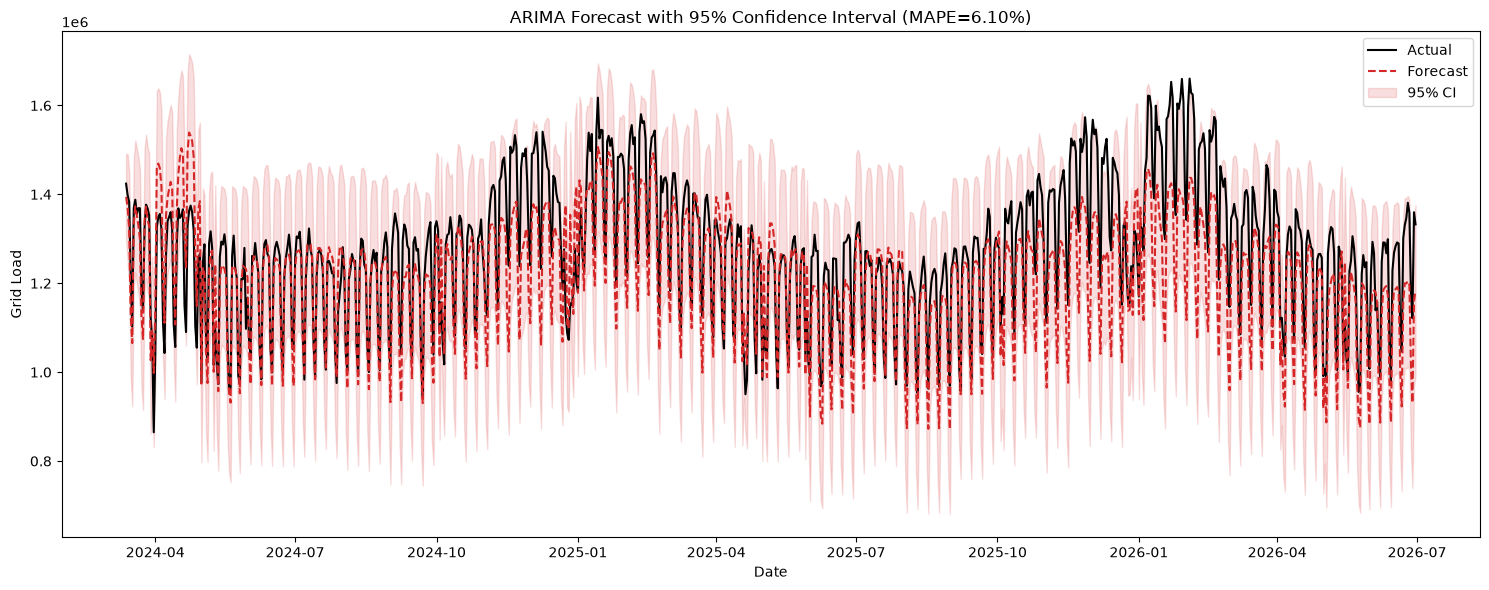

In [21]:
forecast_obj = fit.get_forecast(steps=test_size, exog=exog_test)
forecast_mean = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int(alpha=0.05)  

plt.figure(figsize=(15, 6))
plt.plot(test_dates, y_test.values, label="Actual", color="black", linewidth=1.5)
plt.plot(test_dates, forecast_mean.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.fill_between(
    test_dates,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color="tab:red", alpha=0.15, label="95% CI"
)
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title(f"ARIMA Forecast with 95% Confidence Interval (MAPE={mape:.2%})")
plt.legend()
plt.tight_layout()
plt.show()

##### Running a test on the error finding out if could rely on Forecast

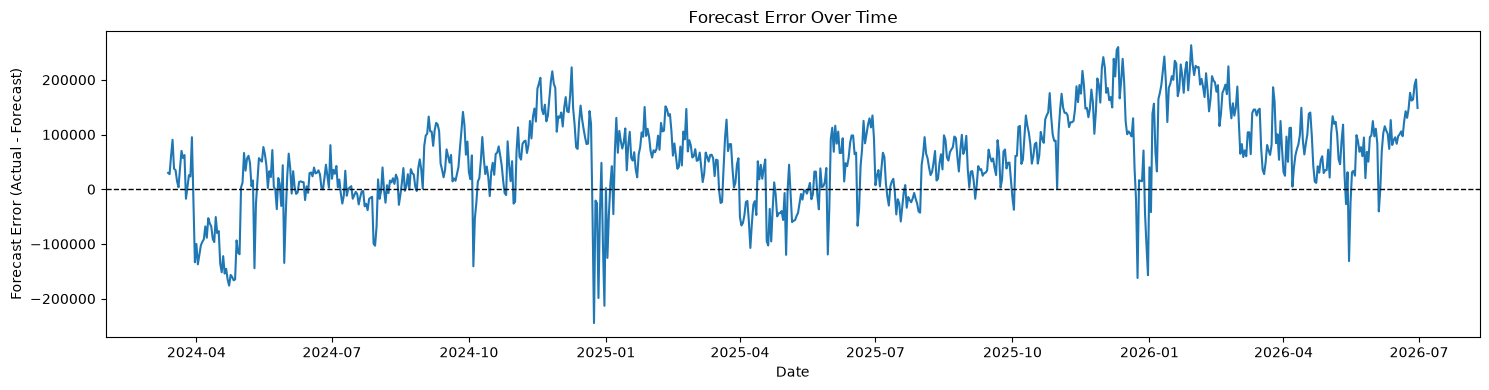

In [22]:
errors = y_test.values - forecast.values

plt.figure(figsize=(15, 4))
plt.plot(test_dates, errors, color="tab:blue")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Forecast Error (Actual - Forecast)")
plt.title("Forecast Error Over Time")
plt.tight_layout()
plt.show()

<div style="text-align:left;">
    <span style="color: red; font-size:14px; font-weight:bold;">
        A growing positive bias overtime, the model is still increasingly underpredicting as the horizon lengthens 
        The erros are too large around christmas time and well before the end of the year
        The model seems to follow much the path of production index and lean towards a down trend
    </span>
</div>

##### We will be adding an holiday period not only holiday date to deal with the low-activity around Christmas and New Year.
##### In order to deal with the Model follow towards the Production index drop we will be introducing an explicit linear time trend to address the MWh/day drift

In [23]:
merged["is_holiday_period"] = (
    ((merged["date"].dt.month == 12) & (merged["date"].dt.day >= 23)) |
    ((merged["date"].dt.month == 1) & (merged["date"].dt.day <= 2))
).astype(int)
merged["time_index"] = np.arange(len(merged))
final_vars = ["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_weekend", "is_holiday","is_holiday_period","time_index"]


X = merged[final_vars].dropna().astype(float)

vif_data = pd.DataFrame()
vif_data["variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data.sort_values("VIF", ascending=False))

                    variable       VIF
3  production_deseasonalized  5.050939
2                  CDD_roll7  4.877999
1                  CDD_roll3  4.626735
7                 time_index  3.346297
0                  HDD_roll3  2.379665
4                 is_weekend  1.401151
6          is_holiday_period  1.146701
5                 is_holiday  1.115745


In [24]:
dow_dummies = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)

exog_vars = pd.concat([
    merged[["HDD_roll3", "CDD_roll3","CDD_roll7", "production_deseasonalized", "is_holiday","is_weekend","is_holiday_period","time_index"]],
    dow_dummies
], axis=1)

y = merged["Grid load [MWh]"]

valid = exog_vars.notna().all(axis=1) & y.notna()
y_valid = y[valid].reset_index(drop=True)
exog_valid = exog_vars[valid].astype(float).reset_index(drop=True)
merged_dates = merged.loc[valid, "date"].reset_index(drop=True)

test_size = 840

y_train, y_test = y_valid.iloc[:-test_size], y_valid.iloc[-test_size:]
exog_train, exog_test = exog_valid.iloc[:-test_size], exog_valid.iloc[-test_size:]

from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=(3,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
fit = model.fit(disp=False)
print(fit.summary())

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                      SARIMAX Results                                      
Dep. Variable:                     Grid load [MWh]   No. Observations:                 3353
Model:             SARIMAX(3, 0, 2)x(1, 0, [1], 7)   Log Likelihood              -40355.727
Date:                             Mon, 21 Sep 2026   AIC                          80755.454
Time:                                     09:48:19   BIC                          80889.976
Sample:                                          0   HQIC                         80803.575
                                            - 3353                                         
Covariance Type:                               opg                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
HDD_roll3                  1.532e+04    627.210     24.421      0.000    1.4

In [25]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

forecast = fit.forecast(steps=test_size, exog=exog_test)
mape = mean_absolute_percentage_error(y_test, forecast)
rmse = np.sqrt(mean_squared_error(y_test, forecast))
print(f"MAPE: {mape:.2%}, RMSE: {rmse:.2f}")

MAPE: 4.55%, RMSE: 75103.04


<div style="text-align:left;">
    <span style="color: purple; font-size:12px; font-weight:bold;">
        An improvmenet of the MAPE lets find out graphically if it comes close to the Actual values
    </span>
</div>

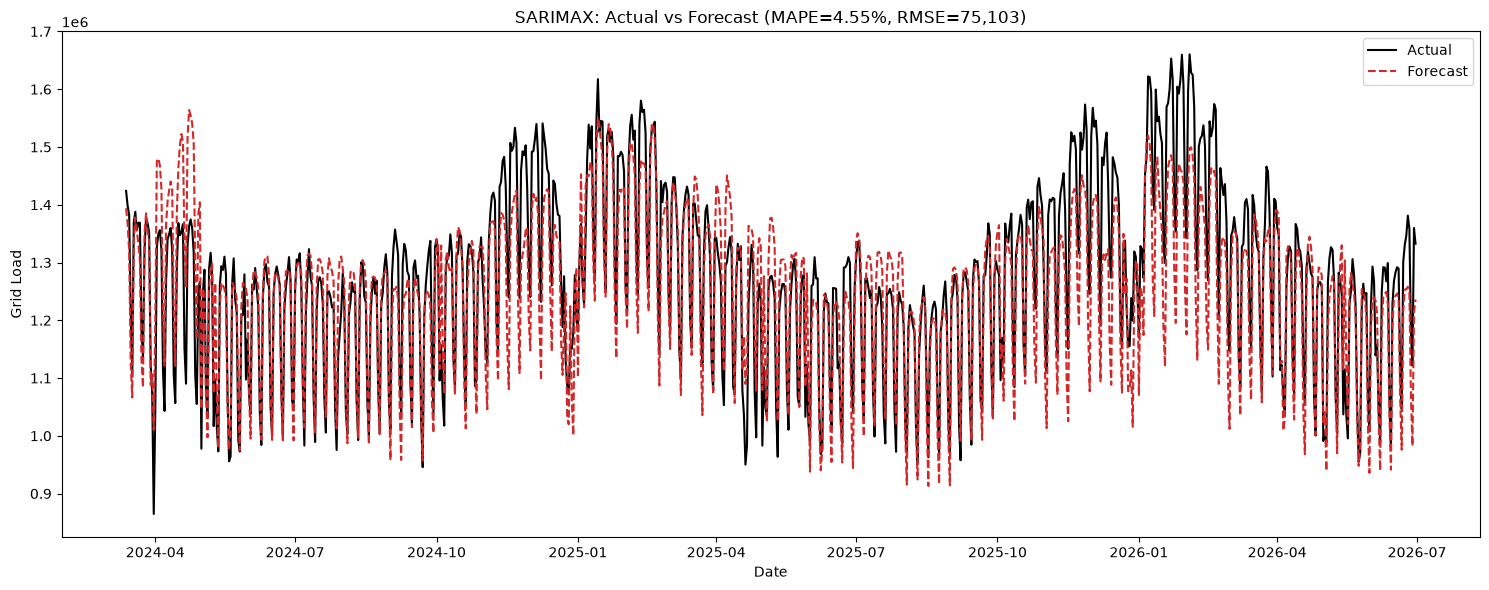

In [26]:
test_dates = merged_dates.iloc[-test_size:]

plt.figure(figsize=(15, 6))
plt.plot(test_dates, y_test.values, label="Actual", color="black", linewidth=1.5)
plt.plot(test_dates, forecast.values, label="Forecast", color="tab:red", linestyle="--", linewidth=1.5)
plt.xlabel("Date")
plt.ylabel("Grid Load")
plt.title(f"SARIMAX: Actual vs Forecast (MAPE={mape:.2%}, RMSE={rmse:,.0f})")
plt.legend()
plt.tight_layout()
plt.show()

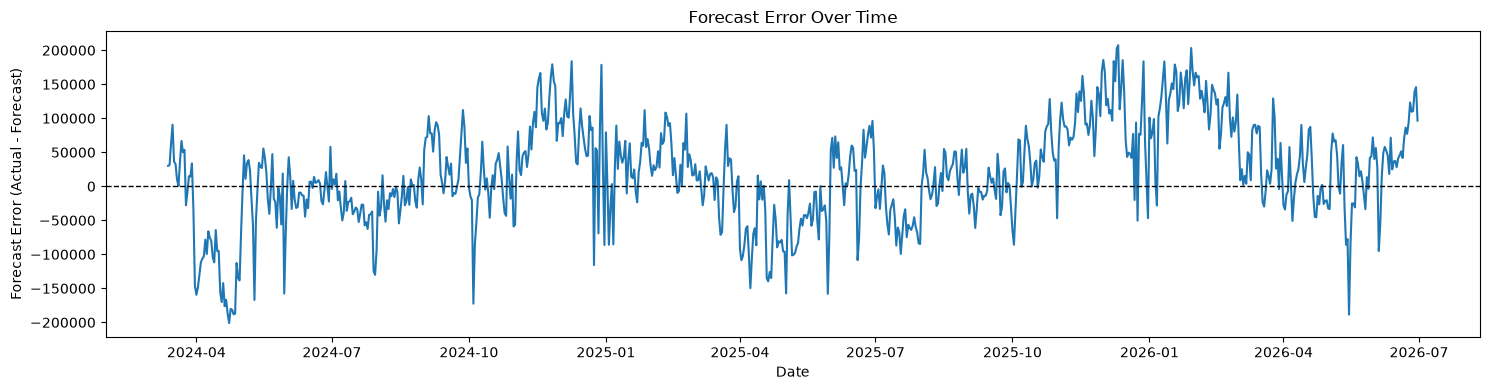

In [27]:
errors = y_test.values - forecast.values

plt.figure(figsize=(15, 4))
plt.plot(test_dates, errors, color="tab:blue")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Forecast Error (Actual - Forecast)")
plt.title("Forecast Error Over Time")
plt.tight_layout()
plt.show()

<div style="text-align:left;">
    <span style="color: red; font-size:14px; font-weight:bold;">
        the MAPE imporving by 27% , the test being particularly large it fails to incoprporate the rebound of the industrial 
        activities in late 2025 and early 2026. A Forecast with a lower period than the 2 years + could give us a MAPE of less than 3%
    </span>
</div>

#### A validation of the results with further checks

In [28]:
from scipy.stats import ttest_1samp

t_stat, p = ttest_1samp(errors, 0)
print(f"Mean error = {errors.mean():,.0f}")
print(f"p-value = {p:.4f}")

Mean error = 19,101
p-value = 0.0000


In [29]:
daily_test_average = y_test.mean()
Mean_error = errors.mean()
Bias = Mean_error/ daily_test_average
print(f"Bias Percentage: {Bias:.2%}")

Bias Percentage: 1.50%


In [30]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, forecast)
print(f"R² = {r2:.4f}")

R² = 0.7675


In [31]:
nrmse = rmse / daily_test_average

print(f"NRMSE = {nrmse:.2%}")

NRMSE = 5.90%


##### The model explains 76% of the variance in daily grid load over an 29-month out-of-sample test period, achieving a mean absolute percentage error of 4.55% and a near-zero bias (1.5%). The relatively moderate R², despite strong percentage accuracy, reflects the high day-to-day variance inherent in daily grid load data (weekly cycles, weather variability) rather than a shortfall in the model's absolute forecasting accuracy."

In [32]:
effects = pd.DataFrame({
    "Variable": [
        "Holiday",
        "Weekend",
        "HDD_roll3",
        "CDD_roll3",
        "Production"
    ],
    "Coefficient": [
        -286300,
        -149500,
        15150,
        10620,
        5046
    ],
    "Interpretation": [
        "Demand decreases by 286,300 MWh on holidays",
        "Demand decreases by 149,500 MWh on weekends",
        "Each additional HDD increases demand by 15,150 MWh",
        "Each additional CDD increases demand by 10,620 MWh",
        "Each production unit increases demand by 5,046 MWh"
    ]
})

effects

,Variable,Coefficient,Interpretation
0,Holiday,-286300,"Demand decreases by 286,300 MWh on holidays"
1,Weekend,-149500,"Demand decreases by 149,500 MWh on weekends"
2,HDD_roll3,15150,"Each additional HDD increases demand by 15,150..."
3,CDD_roll3,10620,"Each additional CDD increases demand by 10,620..."
4,Production,5046,"Each production unit increases demand by 5,046..."


## Part B — Six-Month Load Outlook, Residual Load, and Price Scenarios

This section extends the existing SARIMAX load model **without replacing it**. The objective is to separate three different problems that have very different levels of predictability:

1. **Electricity load** — forecast with the existing SARIMAX structure.
2. **Wind and solar generation** — treated as weather-driven scenarios as the horizon grows.
3. **Electricity price** — treated as a probability/scenario problem rather than a precise 180-day point forecast.

The notebook above reports a final out-of-sample load MAPE of about **4.55%** after adding the Christmas/New-Year period and the linear time index. Remember that this test uses exogenous variables observed over the test period. A real 180-day forecast must also forecast or scenario-generate those future exogenous inputs.


### Part B-1 Wind and solar generation  
using historical day-of-year distributions from SMARD. This gives P10/P50/P90 seasonal renewable scenarios without pretending that we know wind six months in advance.

In [33]:
system_daily = (Production
    .set_index("date")
    .resample("D")
    .agg({
        "Grid load [MWh]": "sum",
        "Onshore Wind [MWh]": "sum",
        "Offshore Wind [MWh]": "sum",
        "Photovoltaics [MWh]": "sum",
    })
    .reset_index()
)

system_daily["Wind [MWh]"] = (
    system_daily["Onshore Wind [MWh]"] + system_daily["Offshore Wind [MWh]"]
)
system_daily["Wind+Solar [MWh]"] = system_daily["Wind [MWh]"] + system_daily["Photovoltaics [MWh]"]
system_daily["Residual load [MWh]"] = (
    system_daily["Grid load [MWh]"] - system_daily["Wind+Solar [MWh]"]
)

system_daily.tail()

,date,Grid load [MWh],Onshore Wind [MWh],Offshore Wind [MWh],Photovoltaics [MWh],Wind [MWh],Wind+Solar [MWh],Residual load [MWh]
4194,2026-06-26,1358261.53,120184.00,49496.14,483169.79,169680.14,652849.93,705411.60
4195,2026-06-27,1180762.65,125652.28,12765.34,452533.37,138417.62,590950.99,589811.66
4196,2026-06-28,1121407.80,196800.05,57565.42,415340.52,254365.47,669705.99,451701.81
4197,2026-06-29,1359768.88,122108.09,14713.65,327428.29,136821.74,464250.03,895518.85
4198,2026-06-30,1332579.91,81826.38,7935.17,361638.87,89761.55,451400.42,881179.49


In [34]:
import holidays

HORIZON = 180
last_model_date = merged["date"].max()
future_dates = pd.date_range(last_model_date + pd.Timedelta(days=1), periods=HORIZON, freq="D")
future = pd.DataFrame({"date": future_dates})

future["day_of_week"] = future["date"].dt.dayofweek
future["is_weekend"] = future["day_of_week"].isin([5, 6]).astype(int)

future_holidays = holidays.Germany(years=sorted(set(future["date"].dt.year)))
future["is_holiday"] = future["date"].isin(future_holidays).astype(int)
future["is_holiday_period"] = (
    ((future["date"].dt.month == 12) & (future["date"].dt.day >= 23)) |
    ((future["date"].dt.month == 1) & (future["date"].dt.day <= 2))
).astype(int)

future["time_index"] = np.arange(len(merged), len(merged) + HORIZON)
future.head()

/var/folders/np/v9js13r17k9_qp03z_bwglkh0000gn/T/ipykernel_16905/1771777887.py:12: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  future["is_holiday"] = future["date"].isin(future_holidays).astype(int)


,date,day_of_week,is_weekend,is_holiday,is_holiday_period,time_index
0,2026-07-01,2,0,0,0,4199
1,2026-07-02,3,0,0,0,4200
2,2026-07-03,4,0,0,0,4201
3,2026-07-04,5,1,0,0,4202
4,2026-07-05,6,1,0,0,4203


In [35]:
temp_hist = result[["date", "Germany_avg_temp"]].dropna().copy()
temp_hist["doy"] = temp_hist["date"].dt.dayofyear

clim = temp_hist.groupby("doy")["Germany_avg_temp"].agg(["mean", "std"])

future["doy"] = future["date"].dt.dayofyear
future = future.join(clim, on="doy")
future["temp_p50"] = future["mean"]
future["temp_cold"] = future["mean"] - future["std"].fillna(3.0)
future["temp_warm"] = future["mean"] + future["std"].fillna(3.0)

future[["date", "temp_cold", "temp_p50", "temp_warm"]].head()

,date,temp_cold,temp_p50,temp_warm
0,2026-07-01,16.293233,19.400000,22.506767
1,2026-07-02,15.992003,19.754545,23.517088
2,2026-07-03,16.194752,19.227273,22.259793
3,2026-07-04,15.543508,19.081818,22.620128
4,2026-07-05,16.544961,19.527273,22.509584


In [36]:
def add_degree_day_features(df, temp_col):
    x = df.copy()
    x["HDD"] = (15.0 - x[temp_col]).clip(lower=0)
    x["CDD"] = (x[temp_col] - 20.0).clip(lower=0)
    x["HDD_roll3"] = x["HDD"].rolling(3, min_periods=1).mean()
    x["CDD_roll3"] = x["CDD"].rolling(3, min_periods=1).mean()
    x["CDD_roll7"] = x["CDD"].rolling(7, min_periods=1).mean()
    return x

future_p50 = add_degree_day_features(future, "temp_p50")
future_cold = add_degree_day_features(future, "temp_cold")
future_warm = add_degree_day_features(future, "temp_warm")

In [37]:
last_prod = merged["production_deseasonalized"].dropna().iloc[-1]
for f in [future_p50, future_cold, future_warm]:
    f["production_deseasonalized"] = last_prod

In [38]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

hist_dow = pd.get_dummies(merged["day_of_week"], prefix="dow", drop_first=True)
hist_exog = pd.concat([
    merged[["HDD_roll3", "CDD_roll3", "CDD_roll7", "production_deseasonalized",
            "is_holiday", "is_weekend", "is_holiday_period", "time_index"]],
    hist_dow
], axis=1).astype(float)

hist_y = merged["Grid load [MWh]"]
valid_full = hist_exog.notna().all(axis=1) & hist_y.notna()
X_full = hist_exog.loc[valid_full].reset_index(drop=True)
y_full = hist_y.loc[valid_full].reset_index(drop=True)

final_fit = SARIMAX(
    y_full,
    exog=X_full,
    order=(3,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

feature_cols = list(X_full.columns)

def future_exog(frame):
    dow = pd.get_dummies(frame["day_of_week"], prefix="dow", drop_first=True)
    X = pd.concat([
        frame[["HDD_roll3", "CDD_roll3", "CDD_roll7", "production_deseasonalized",
               "is_holiday", "is_weekend", "is_holiday_period", "time_index"]],
        dow
    ], axis=1)
    
    return X.reindex(columns=feature_cols, fill_value=0).astype(float)

load_p50 = final_fit.forecast(HORIZON, exog=future_exog(future_p50))
load_cold = final_fit.forecast(HORIZON, exog=future_exog(future_cold))
load_warm = final_fit.forecast(HORIZON, exog=future_exog(future_warm))

load_outlook = pd.DataFrame({
    "date": future_dates,
    "load_cold_weather": np.asarray(load_cold),
    "load_p50": np.asarray(load_p50),
    "load_warm_weather": np.asarray(load_warm),
})
load_outlook.head()

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,date,load_cold_weather,load_p50,load_warm_weather
0,2026-07-01,1.306327e+06,1.306327e+06,1.323829e+06
1,2026-07-02,1.298957e+06,1.298957e+06,1.319986e+06
2,2026-07-03,1.269658e+06,1.269658e+06,1.288937e+06
3,2026-07-04,1.086907e+06,1.086907e+06,1.106832e+06
4,2026-07-05,1.017841e+06,1.017841e+06,1.033889e+06


In [39]:
ren_hist = system_daily.copy()
ren_hist["doy"] = ren_hist["date"].dt.dayofyear

ren_clim = ren_hist.groupby("doy").agg(
    wind_p10=("Wind [MWh]", lambda s: s.quantile(0.10)),
    wind_p50=("Wind [MWh]", "median"),
    wind_p90=("Wind [MWh]", lambda s: s.quantile(0.90)),
    solar_p10=("Photovoltaics [MWh]", lambda s: s.quantile(0.10)),
    solar_p50=("Photovoltaics [MWh]", "median"),
    solar_p90=("Photovoltaics [MWh]", lambda s: s.quantile(0.90)),
).reset_index()

outlook = load_outlook.copy()
outlook["doy"] = outlook["date"].dt.dayofyear
outlook = outlook.merge(ren_clim, on="doy", how="left")

outlook["residual_p50"] = outlook["load_p50"] - outlook["wind_p50"] - outlook["solar_p50"]

outlook["residual_tight"] = (
    outlook[["load_cold_weather", "load_warm_weather"]].max(axis=1)
    - outlook["wind_p10"] - outlook["solar_p10"]
)

outlook["residual_loose"] = (
    outlook[["load_cold_weather", "load_warm_weather"]].min(axis=1)
    - outlook["wind_p90"] - outlook["solar_p90"]
)

outlook[["date", "load_p50", "wind_p50", "solar_p50", "residual_p50"]].head()

,date,load_p50,wind_p50,solar_p50,residual_p50
0,2026-07-01,1.306327e+06,290534.12,197005.75,818787.057130
1,2026-07-02,1.298957e+06,235393.25,217844.75,845719.167499
2,2026-07-03,1.269658e+06,274749.06,228321.00,766588.224678
3,2026-07-04,1.086907e+06,205010.05,203375.50,678521.808312
4,2026-07-05,1.017841e+06,220111.00,201794.36,595935.436521


### Part B-2 Scenario and Model

Calendar variables are known perfectly in advance. Weather and industrial production are not. We therefore create the future dates first and then fill each exogenous variable according to its uncertainty.

Add price data before fitting a price model

In [40]:
from sklearn.ensemble import HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

price_features = [
    "Residual load [MWh]", "Wind [MWh]", "Photovoltaics [MWh]"
]

if "price_training" in globals() and PRICE_COL in price_training.columns:
    pt = price_training.dropna(subset=price_features + [PRICE_COL]).copy()
    pt["month"] = pt["date"].dt.month
    pt["dow"] = pt["date"].dt.dayofweek
    price_features_ext = price_features + ["month", "dow"]

    # Time split — never random split a time series
    split = int(len(pt) * 0.8)
    Xtr, Xte = pt[price_features_ext].iloc[:split], pt[price_features_ext].iloc[split:]
    ytr, yte = pt[PRICE_COL].iloc[:split], pt[PRICE_COL].iloc[split:]

    price_model = HistGradientBoostingRegressor(max_depth=5, learning_rate=0.05, max_iter=400, random_state=42)
    price_model.fit(Xtr, ytr)
    pred = price_model.predict(Xte)

    print("Price MAE:", mean_absolute_error(yte, pred))
    print("Price RMSE:", np.sqrt(mean_squared_error(yte, pred)))
else:
    print("Price model skipped: merge the SMARD Day-Ahead price data first.")

Price model skipped: merge the SMARD Day-Ahead price data first.


In [41]:
PRICE_COL = "Price [€/MWh]"

In [42]:
energy = pd.read_csv("/Users/jeanmiccheltia/Downloads/Energy.csv")

energy["date"] = pd.to_datetime(energy["date"])

PRICE_COL = "Price [€/MWh]"

print(energy[PRICE_COL].describe())
print("Missing prices:", energy[PRICE_COL].isna().sum())

count    2830.000000
mean       93.627261
std        83.078248
min       -53.870000
25%        42.012500
50%        74.240000
75%       110.205000
max       699.440000
Name: Price [€/MWh], dtype: float64
Missing prices: 1369


In [43]:
price_data = energy[
    energy[PRICE_COL].notna()
].copy()

print("Price model start:", price_data["date"].min())
print("Price model end:", price_data["date"].max())
print("Observations:", len(price_data))

Price model start: 2018-10-01 00:00:00
Price model end: 2026-06-30 00:00:00
Observations: 2830


In [44]:
print("Missing prices:", price_data[PRICE_COL].isna().sum())

Missing prices: 0


In [45]:
print(price_data.columns.tolist())

['date', 'Biomass', 'Hydropower', 'Offshore Wind', 'Onshore Wind [MWh]', 'Photovoltaics', 'Other renewables', 'Nuclear energy', 'Lignite', 'Hard coal', 'Natural gas', 'Pumped-storage', 'Other Conventional', 'Grid load [MWh]', 'Price [€/MWh]', 'Avg_temp', 'Prod_index']


In [46]:
price_data = price_data.sort_values("date").copy()

# Renewable generation
price_data["Wind [MWh]"] = (
    price_data["Offshore Wind"] +
    price_data["Onshore Wind [MWh]"]
)

# Residual load
price_data["Residual load [MWh]"] = (
    price_data["Grid load [MWh]"]
    - price_data["Wind [MWh]"]
    - price_data["Photovoltaics"]
)

# Calendar variables
price_data["month"] = price_data["date"].dt.month
price_data["day_of_week"] = price_data["date"].dt.dayofweek

In [47]:
price_data["price_lag_1"] = price_data["Price [€/MWh]"].shift(1)
price_data["price_lag_7"] = price_data["Price [€/MWh]"].shift(7)

price_data["price_rolling_7"] = (
    price_data["Price [€/MWh]"]
    .shift(1)
    .rolling(7)
    .mean()
)

In [48]:
features = [
    "Residual load [MWh]",
    "Wind [MWh]",
    "Photovoltaics",
    "Natural gas",
    "Hard coal",
    "Lignite",
    "Avg_temp",
    "Prod_index",
    "month",
    "day_of_week",
    "price_lag_1",
    "price_lag_7",
    "price_rolling_7"
]

target = "Price [€/MWh]"

In [49]:
model_data = price_data[
    ["date"] + features + [target]
].dropna().copy()

print(model_data.shape)

(91, 15)


### Part b-3 Model Price Forecast based on previous Model

split = int(len(model_data) * 0.8)

train = model_data.iloc[:split].copy()
test = model_data.iloc[split:].copy()

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("Train:", train["date"].min(), "to", train["date"].max())
print("Test:", test["date"].min(), "to", test["date"].max())

In [50]:
price_data["price_lag_1"] = price_data[PRICE_COL].shift(1)
price_data["price_lag_7"] = price_data[PRICE_COL].shift(7)

price_data["price_rolling_7"] = (
    price_data[PRICE_COL]
    .shift(1)
    .rolling(7)
    .mean()
)
price_features = [
    "Residual load [MWh]",
    "Wind [MWh]",
    "Photovoltaics",
    "price_lag_1",
    "price_lag_7",
    "price_rolling_7"
]

pt = price_data.dropna(
    subset=price_features + [PRICE_COL]
).copy()

pt["month"] = pt["date"].dt.month
pt["dow"] = pt["date"].dt.dayofweek

price_features_ext = price_features + ["month", "dow"]


split = int(len(pt) * 0.8)

Xtr = pt[price_features_ext].iloc[:split]
Xte = pt[price_features_ext].iloc[split:]

ytr = pt[PRICE_COL].iloc[:split]
yte = pt[PRICE_COL].iloc[split:]

price_model = HistGradientBoostingRegressor(
    max_depth=5,
    learning_rate=0.05,
    max_iter=400,
    random_state=42
)

price_model.fit(Xtr, ytr)

pred = price_model.predict(Xte)

print("Price MAE:", mean_absolute_error(yte, pred))
print(
    "Price RMSE:",
    np.sqrt(mean_squared_error(yte, pred))
)

Price MAE: 15.80374377727936
Price RMSE: 21.227066775626827


German power prices can be close to zero or negative, which makes percentage errors unstable. Prefer MAE, RMSE, median absolute error, and prediction-interval coverage.
The MAE is 15.08 and Price RMSE 21.22    

MAE = 15.80 €/MWh: On average, the predicted electricity price is about €15.80/MWh away from the actual price.
RMSE = 21.23 €/MWh: The typical error is about €21.23/MWh, with larger errors penalized more heavily.
Since RMSE > MAE, the model has some relatively large prediction errors.

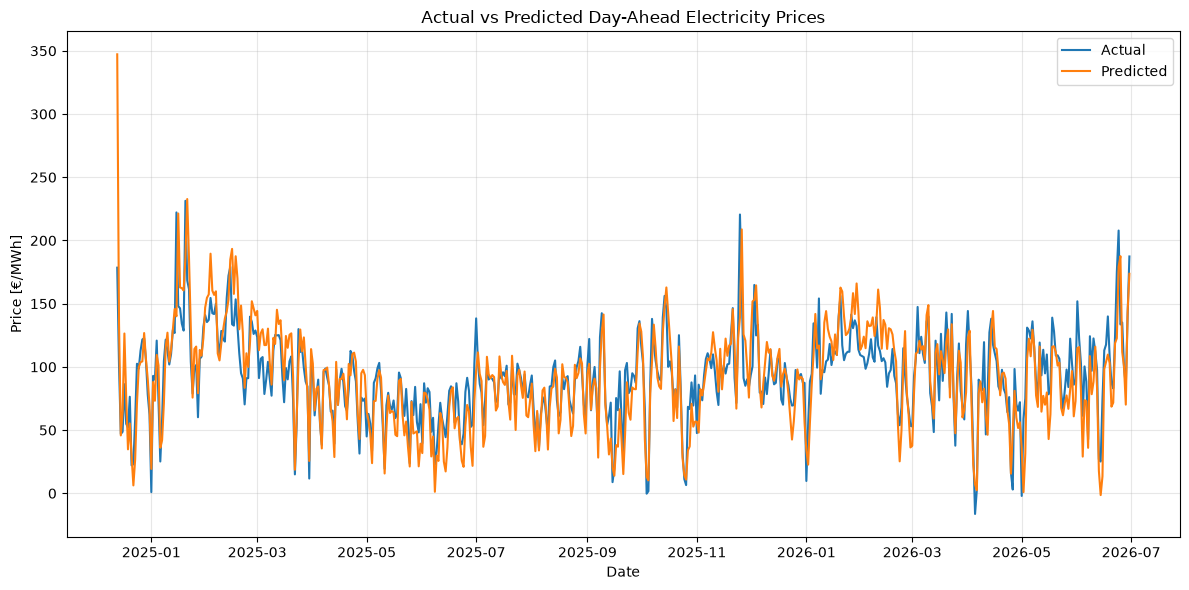

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    pt["date"].iloc[split:],
    yte.values,
    label="Actual"
)

plt.plot(
    pt["date"].iloc[split:],
    pred,
    label="Predicted"
)

plt.xlabel("Date")
plt.ylabel("Price [€/MWh]")
plt.title("Actual vs Predicted Day-Ahead Electricity Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [52]:
residuals = yte.values - pred

print("Mean residual:", residuals.mean())
print("Median residual:", np.median(residuals))
print("Residual std:", residuals.std())

Mean residual: 0.6413631694221475
Median residual: 2.1428769232543345
Residual std: 21.21737536034627


the model has little systematic bias, but individual price predictions can still have fairly large errors.

Check the model to validate it

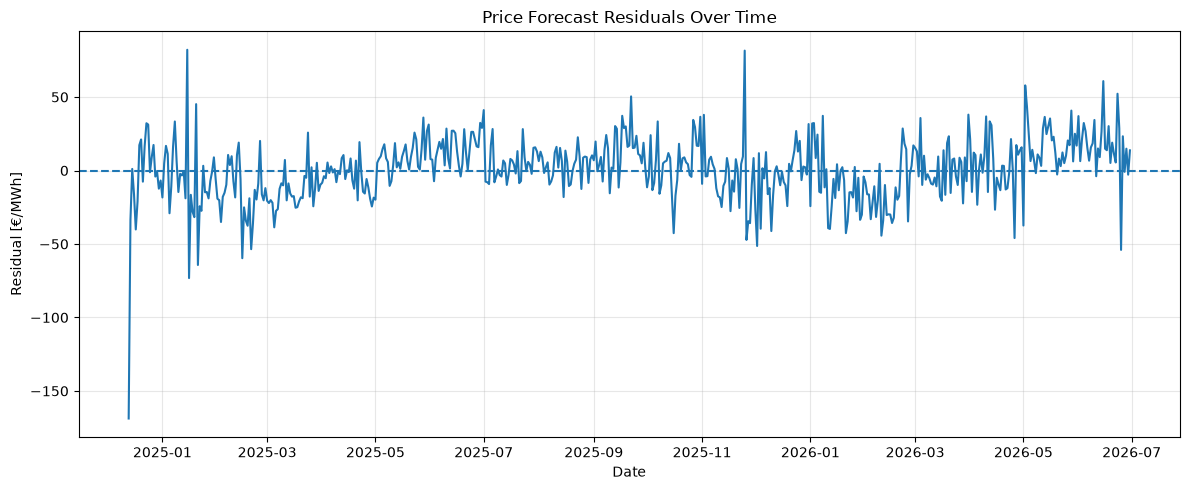

In [53]:
plt.figure(figsize=(12, 5))

plt.plot(
    pt["date"].iloc[split:],
    residuals
)

plt.axhline(0, linestyle="--")

plt.xlabel("Date")
plt.ylabel("Residual [€/MWh]")
plt.title("Price Forecast Residuals Over Time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

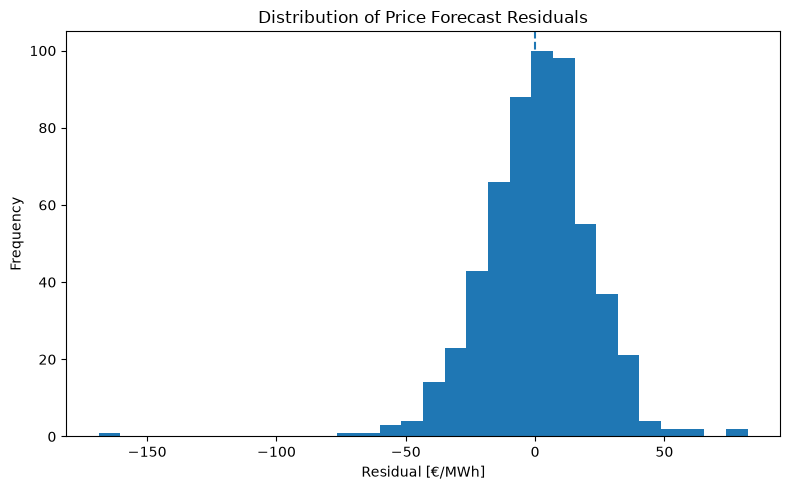

In [54]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30)

plt.axvline(0, linestyle="--")
plt.xlabel("Residual [€/MWh]")
plt.ylabel("Frequency")
plt.title("Distribution of Price Forecast Residuals")
plt.tight_layout()
plt.show()

### Quantile price models: P10, P50 and P90

P10: a low-price system outcome;
P50: the median/base outcome;
P90: a high-price/tight-system outcome.

In [55]:
if "price_training" in globals() and PRICE_COL in price_training.columns:
    pt = price_training.dropna(subset=price_features + [PRICE_COL]).copy()
    pt["month"] = pt["date"].dt.month
    pt["dow"] = pt["date"].dt.dayofweek
    q_features = price_features + ["month", "dow"]

    split = int(len(pt) * 0.8)
    Xtr, Xte = pt[q_features].iloc[:split], pt[q_features].iloc[split:]
    ytr, yte = pt[PRICE_COL].iloc[:split], pt[PRICE_COL].iloc[split:]

    q_models = {}
    for q in [0.10, 0.50, 0.90]:
        m = GradientBoostingRegressor(
            loss="quantile", alpha=q,
            n_estimators=350, learning_rate=0.03,
            max_depth=3, random_state=42
        )
        m.fit(Xtr, ytr)
        q_models[q] = m

    # Interval coverage on the hold-out period
    p10 = q_models[0.10].predict(Xte)
    p50 = q_models[0.50].predict(Xte)
    p90 = q_models[0.90].predict(Xte)
    coverage = np.mean((yte.values >= p10) & (yte.values <= p90))
    print(f"P10-P90 empirical coverage: {coverage:.1%}")

Addition of an horizon 

In [56]:
from sklearn.metrics import mean_absolute_percentage_error

horizons = [7, 30, 90, 180]
rows = []
for h in horizons:
    if len(y_test) >= h:
        rows.append({
            "horizon_days": h,
            "MAPE": mean_absolute_percentage_error(y_test.iloc[:h], forecast.iloc[:h])
        })

horizon_report = pd.DataFrame(rows)
horizon_report

,horizon_days,MAPE
0,7,0.032511
1,30,0.053581
2,90,0.056963
3,180,0.041385


In [57]:
dashboard_outlook = outlook[[
    "date",
    "load_cold_weather", "load_p50", "load_warm_weather",
    "wind_p10", "wind_p50", "wind_p90",
    "solar_p10", "solar_p50", "solar_p90",
    "residual_loose", "residual_p50", "residual_tight"
]].copy()

dashboard_outlook.to_csv("dashboard_180d_outlook.csv", index=False)
dashboard_outlook.head()

,date,load_cold_weather,load_p50,load_warm_weather,wind_p10,wind_p50,wind_p90,solar_p10,solar_p50,solar_p90,residual_loose,residual_p50,residual_tight
0,2026-07-01,1.306327e+06,1.306327e+06,1.323829e+06,146344.72,290534.12,483118.75,109136.40,197005.75,254952.99,568255.187130,818787.057130,1.068348e+06
1,2026-07-02,1.298957e+06,1.298957e+06,1.319986e+06,155316.42,235393.25,399712.25,166392.76,217844.75,334460.50,564784.417499,845719.167499,9.982771e+05
2,2026-07-03,1.269658e+06,1.269658e+06,1.288937e+06,86538.67,274749.06,383883.66,171347.75,228321.00,320000.50,565774.124678,766588.224678,1.031050e+06
3,2026-07-04,1.086907e+06,1.086907e+06,1.106832e+06,57310.25,205010.05,297846.25,194376.48,203375.50,286758.75,502302.358312,678521.808312,8.551458e+05
4,2026-07-05,1.017841e+06,1.017841e+06,1.033889e+06,60450.02,220111.00,603532.25,172509.25,201794.36,286033.75,128274.796521,595935.436521,8.009295e+05


### Creation of an horizon

## Partb-4 Dashboards Creation

In [58]:
if "dashboard_outlook" not in globals():
    raise RuntimeError(
        "Run Part A through Step 12 first. "
        "`dashboard_outlook` must exist before building the dashboard."
    )

dash = dashboard_outlook.copy()
dash["date"] = pd.to_datetime(dash["date"])
dash = dash.sort_values("date").reset_index(drop=True)

print("Dashboard rows:", len(dash))
print("Forecast period:", dash["date"].min(), "to", dash["date"].max())
display(dash.head())

Dashboard rows: 180
Forecast period: 2026-07-01 00:00:00 to 2026-12-27 00:00:00


,date,load_cold_weather,load_p50,load_warm_weather,wind_p10,wind_p50,wind_p90,solar_p10,solar_p50,solar_p90,residual_loose,residual_p50,residual_tight
0,2026-07-01,1.306327e+06,1.306327e+06,1.323829e+06,146344.72,290534.12,483118.75,109136.40,197005.75,254952.99,568255.187130,818787.057130,1.068348e+06
1,2026-07-02,1.298957e+06,1.298957e+06,1.319986e+06,155316.42,235393.25,399712.25,166392.76,217844.75,334460.50,564784.417499,845719.167499,9.982771e+05
2,2026-07-03,1.269658e+06,1.269658e+06,1.288937e+06,86538.67,274749.06,383883.66,171347.75,228321.00,320000.50,565774.124678,766588.224678,1.031050e+06
3,2026-07-04,1.086907e+06,1.086907e+06,1.106832e+06,57310.25,205010.05,297846.25,194376.48,203375.50,286758.75,502302.358312,678521.808312,8.551458e+05
4,2026-07-05,1.017841e+06,1.017841e+06,1.033889e+06,60450.02,220111.00,603532.25,172509.25,201794.36,286033.75,128274.796521,595935.436521,8.009295e+05


In [59]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

median_load = dash["load_p50"].median()
peak_load = dash["load_p50"].max()
median_residual = dash["residual_p50"].median()
max_tight_residual = dash["residual_tight"].max()

cards = f'''
<div style="display:flex; gap:14px; flex-wrap:wrap; margin:8px 0 18px 0;">
  <div style="padding:16px 20px;border:1px solid #ddd;border-radius:12px;min-width:170px">
    <div style="font-size:13px;color:#666">Median Load</div>
    <div style="font-size:25px;font-weight:700">{median_load:,.0f} MWh/day</div>
  </div>
  <div style="padding:16px 20px;border:1px solid #ddd;border-radius:12px;min-width:170px">
    <div style="font-size:13px;color:#666">Peak Load</div>
    <div style="font-size:25px;font-weight:700">{peak_load:,.0f} MWh/day</div>
  </div>
  <div style="padding:16px 20px;border:1px solid #ddd;border-radius:12px;min-width:170px">
    <div style="font-size:13px;color:#666">Median Residual Load</div>
    <div style="font-size:25px;font-weight:700">{median_residual:,.0f} MWh/day</div>
  </div>
  <div style="padding:16px 20px;border:1px solid #ddd;border-radius:12px;min-width:170px">
    <div style="font-size:13px;color:#666">Max Tight Residual Load</div>
    <div style="font-size:25px;font-weight:700">{max_tight_residual:,.0f} MWh/day</div>
  </div>
</div>
'''
display(HTML(cards))

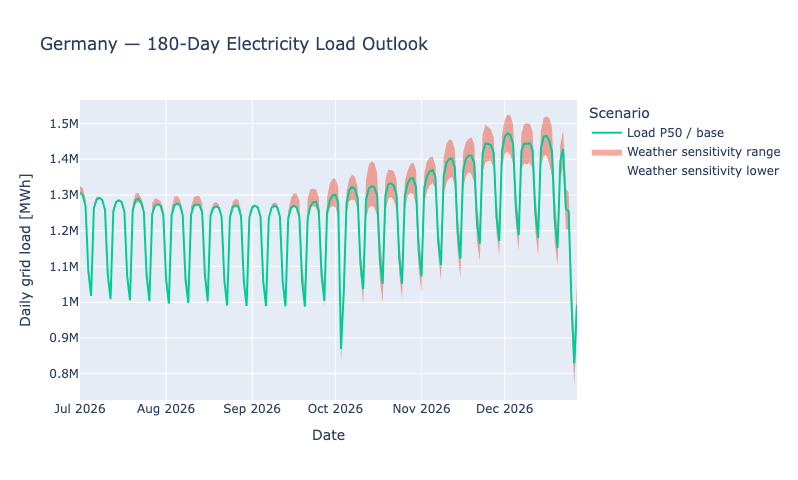

In [60]:
fig_load = go.Figure()

lower_load = dash[["load_cold_weather", "load_warm_weather"]].min(axis=1)
upper_load = dash[["load_cold_weather", "load_warm_weather"]].max(axis=1)

fig_load.add_trace(go.Scatter(
    x=dash["date"], y=lower_load,
    mode="lines", line=dict(width=0),
    name="Weather sensitivity lower",
    hoverinfo="skip"
))
fig_load.add_trace(go.Scatter(
    x=dash["date"], y=upper_load,
    mode="lines", line=dict(width=0),
    fill="tonexty",
    name="Weather sensitivity range",
    hovertemplate="%{x|%Y-%m-%d}<br>Upper scenario: %{y:,.0f} MWh<extra></extra>"
))
fig_load.add_trace(go.Scatter(
    x=dash["date"], y=dash["load_p50"],
    mode="lines",
    name="Load P50 / base",
    hovertemplate="%{x|%Y-%m-%d}<br>Load: %{y:,.0f} MWh<extra></extra>"
))

fig_load.update_layout(
    title="Germany — 180-Day Electricity Load Outlook",
    xaxis_title="Date",
    yaxis_title="Daily grid load [MWh]",
    hovermode="x unified",
    legend_title="Scenario",
    height=480
)
fig_load.show()

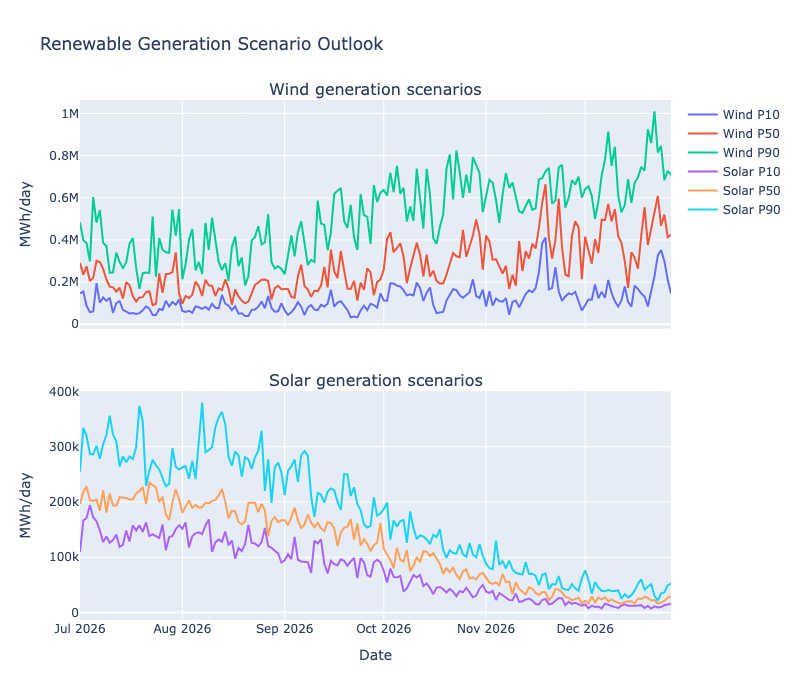

In [61]:
fig_ren = make_subplots(
    rows=2, cols=1, shared_xaxes=True,
    subplot_titles=("Wind generation scenarios", "Solar generation scenarios"),
    vertical_spacing=0.12
)

for col, label in [
    ("wind_p10", "Wind P10"),
    ("wind_p50", "Wind P50"),
    ("wind_p90", "Wind P90"),
]:
    fig_ren.add_trace(
        go.Scatter(x=dash["date"], y=dash[col], mode="lines", name=label),
        row=1, col=1
    )

for col, label in [
    ("solar_p10", "Solar P10"),
    ("solar_p50", "Solar P50"),
    ("solar_p90", "Solar P90"),
]:
    fig_ren.add_trace(
        go.Scatter(x=dash["date"], y=dash[col], mode="lines", name=label),
        row=2, col=1
    )

fig_ren.update_yaxes(title_text="MWh/day", row=1, col=1)
fig_ren.update_yaxes(title_text="MWh/day", row=2, col=1)
fig_ren.update_xaxes(title_text="Date", row=2, col=1)
fig_ren.update_layout(
    title="Renewable Generation Scenario Outlook",
    height=700,
    hovermode="x unified"
)
fig_ren.show()

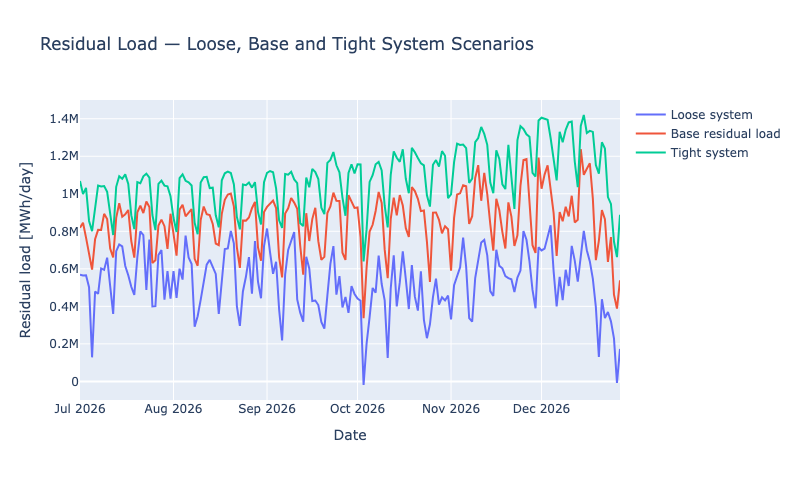

In [62]:
fig_res = go.Figure()

fig_res.add_trace(go.Scatter(
    x=dash["date"], y=dash["residual_loose"],
    mode="lines", name="Loose system"
))
fig_res.add_trace(go.Scatter(
    x=dash["date"], y=dash["residual_p50"],
    mode="lines", name="Base residual load"
))
fig_res.add_trace(go.Scatter(
    x=dash["date"], y=dash["residual_tight"],
    mode="lines", name="Tight system"
))

fig_res.update_layout(
    title="Residual Load — Loose, Base and Tight System Scenarios",
    xaxis_title="Date",
    yaxis_title="Residual load [MWh/day]",
    hovermode="x unified",
    height=480
)
fig_res.show()

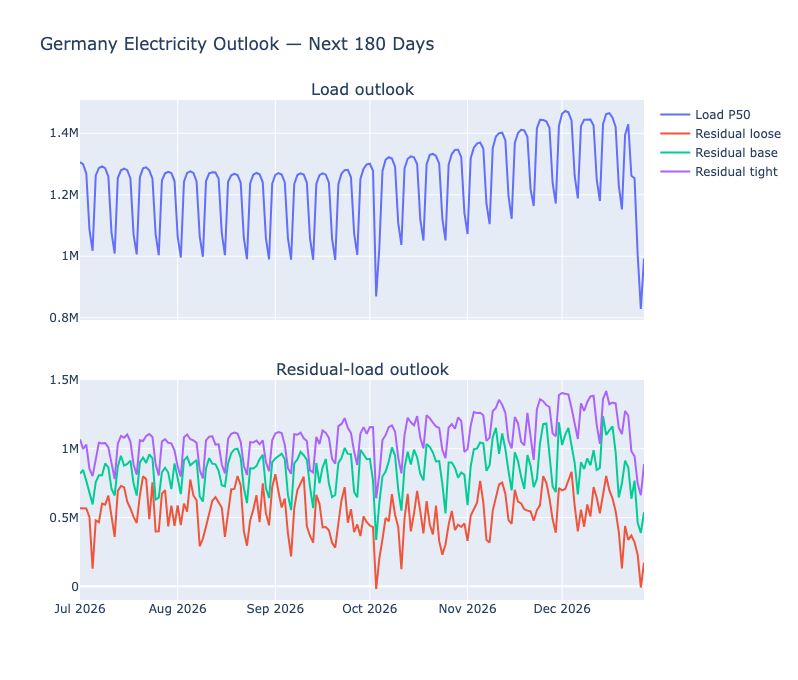

In [63]:
DASHBOARD_HORIZON = 180

if DASHBOARD_HORIZON not in [7, 30, 90, 180]:
    raise ValueError("Choose 7, 30, 90 or 180 days.")

view = dash.head(DASHBOARD_HORIZON)

fig_h = make_subplots(
    rows=2, cols=1, shared_xaxes=True,
    subplot_titles=("Load outlook", "Residual-load outlook"),
    vertical_spacing=0.12
)

fig_h.add_trace(
    go.Scatter(x=view["date"], y=view["load_p50"], mode="lines", name="Load P50"),
    row=1, col=1
)
fig_h.add_trace(
    go.Scatter(x=view["date"], y=view["residual_loose"], mode="lines", name="Residual loose"),
    row=2, col=1
)
fig_h.add_trace(
    go.Scatter(x=view["date"], y=view["residual_p50"], mode="lines", name="Residual base"),
    row=2, col=1
)
fig_h.add_trace(
    go.Scatter(x=view["date"], y=view["residual_tight"], mode="lines", name="Residual tight"),
    row=2, col=1
)

fig_h.update_layout(
    title=f"Germany Electricity Outlook — Next {DASHBOARD_HORIZON} Days",
    height=680,
    hovermode="x unified"
)
fig_h.show()

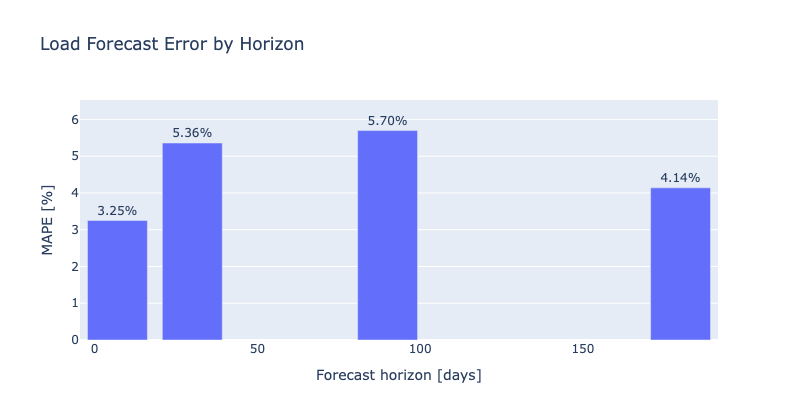

In [64]:
if "horizon_report" in globals() and len(horizon_report) > 0:
    fig_val = go.Figure(
        go.Bar(
            x=horizon_report["horizon_days"],
            y=100 * horizon_report["MAPE"],
            text=(100 * horizon_report["MAPE"]).round(2),
            texttemplate="%{text:.2f}%",
            textposition="outside"
        )
    )
    fig_val.update_layout(
        title="Load Forecast Error by Horizon",
        xaxis_title="Forecast horizon [days]",
        yaxis_title="MAPE [%]",
        height=420
    )
    fig_val.show()
else:
    print("Run the horizon-specific backtest cell in Part A to display this panel.")

In [65]:
required_price_cols = {"price_p10", "price_p50", "price_p90"}

if required_price_cols.issubset(dash.columns):
    fig_price = go.Figure()

    fig_price.add_trace(go.Scatter(
        x=dash["date"], y=dash["price_p10"],
        mode="lines", line=dict(width=0),
        name="Price P10"
    ))
    fig_price.add_trace(go.Scatter(
        x=dash["date"], y=dash["price_p90"],
        mode="lines", line=dict(width=0),
        fill="tonexty",
        name="P10-P90 price range"
    ))
    fig_price.add_trace(go.Scatter(
        x=dash["date"], y=dash["price_p50"],
        mode="lines",
        name="Price P50"
    ))

    fig_price.update_layout(
        title="EXPERIMENTAL — Electricity Price Scenario Range",
        xaxis_title="Date",
        yaxis_title="EUR/MWh",
        hovermode="x unified",
        height=480
    )
    fig_price.show()
else:
    print(
        "Price panel not shown. This is intentional: no validated P10/P50/P90 "
        "price scenarios have been attached to `dashboard_outlook` yet."
    )

Price panel not shown. This is intentional: no validated P10/P50/P90 price scenarios have been attached to `dashboard_outlook` yet.
